# LGBM Workflow V1.4

- Esta version optimiza abril+mayo y valida en junio. Busca obtener hiperparametros podados. <br>
Workflow: <br>
1) Optimización Optuna con rangos acotados entrenamiento abril+mayo validación en junio.
2) Validación temporal con SSS, mejores 10 trials, 50-50
    - Backtest A: Train Abril y Validación Mayo. Priorizar esta para eleccion.
    - Backest B: Train Mayo y Validación Junio
3) Elegir los 5 mejores trials previos y validarlos con pseudo-public-private particionando Junio en 25-75. 
        - Probar primero 50 splits, si es rapido pasar a 500. 
        - Calcular media de ganancia (total no por mes), desviacion, P10/P25, ranking medio, frecuencia de top-1/top-3, regret. Exponiendo tablas separadas para public y private
        - El regret es max Gain_private_i - max_gain_private* ("¿qué tan peligroso sería confiar en mi leaderboard público?")

- La idea es incorporar revalidacion temporal y particion publico-privado.
- Se elimina ccajas_depositos por tener todo cero en mayo
- Entrenamiento final varia.
- Predicción y exportación: agosto.
4) Aumento manual de algunos hiperparametros para entrenamiento definitivo abril+mayo+junio
        -Podria ser min_sum_hessian_in_leaf, num_boost_round y algunos mas
5) Ensamble de 10 semillas para modelo final. 
        -Tambien podria hacerse ensamble de 2 o 3 mejores configuraciones x 6 semillas
        


## Librerias y Dataset

In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone, timedelta

from tqdm.notebook import tqdm

from scipy.stats import gaussian_kde
from scipy.stats import ks_2samp

from sklearn.tree import DecisionTreeClassifier, plot_tree,  _tree
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ShuffleSplit, StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

import lightgbm as lgb


from joblib import Parallel, delayed

import optuna
from optuna.visualization import plot_optimization_history, plot_param_importances, plot_slice, plot_contour

from time import time
from time import perf_counter

import pickle


In [2]:
# from pathlib import Path

# print("Directorio de trabajo:", Path.cwd())
# print("Ruta que se intenta leer:",
#       Path("buckets/b1/datasets/competencia_01_fe_v3.parquet").resolve())

In [3]:
base_path = '/home/ds/buckets/b1'
dataset_path = base_path + '/datasets/'
modelos_path = base_path + '/V1/modelos/'
db_path = base_path + '/V1/db/'
dataset_file = 'competencia_01_fe_v3.parquet'
#buckets/b1/datasets/competencia_01_fe_v3.parquet

# Métricas
ganancia_acierto = 1_072_500
costo_estimulo = 27_500

# Dataframe
data = pd.read_parquet(dataset_path + dataset_file)

In [4]:
# Semillas
semilla = 12
np.random.seed(semilla)
semillas = [12, 2000, 2001, 2003, 2007] 

In [5]:
# Se dropean columnas asociadas a ccajas_depositos
data.drop(
    columns=data.columns[data.columns.str.contains('ccajas_depositos', regex=False)],
    inplace=True
)

## Transformaciones Iniciales

In [6]:
data['clase_peso'] = 1.0

data.loc[data['clase_ternaria'] == 'BAJA+2', 'clase_peso'] = 1.00002
data.loc[data['clase_ternaria'] == 'BAJA+1', 'clase_peso'] = 1.00001 #este es un truco para poder distinguirlos y calcular correctamente la ganancia

In [7]:
data['clase_binaria1'] = 0
data['clase_binaria2'] = 0
data['clase_binaria1'] = np.where(data['clase_ternaria'] == 'BAJA+2', 1, 0)
data['clase_binaria2'] = np.where(data['clase_ternaria'] == 'CONTINUA', 0, 1)

In [8]:
# Funcion de ganancia que use cursada anterior
def lgb_gan_eval(y_pred, data):
    weight = data.get_weight()
    ganancia = np.where(weight == 1.00002, ganancia_acierto, 0) - np.where(weight < 1.00002, costo_estimulo, 0)
    ganancia = ganancia[np.argsort(-y_pred, kind="stable")]
    ganancia = np.cumsum(ganancia)

    return 'gan_eval', max(0.0, float(np.max(ganancia))), True

El target de entrenamiento agrupa BAJA+1 y BAJA+2; la ganancia premia solo BAJA+2.

## Deficiniones temporales
Entrenamiento: abril y mayo completo

Validación: junio completo.

In [9]:
# Definición temporal
meses_train = [202104, 202105]
mes_valid = 202106

# fraccion_continua = 0.30

# def muestrear_continua(df, fraccion=0.30, seed=12):
#     bajas = df.loc[df["clase_ternaria"].isin(["BAJA+1", "BAJA+2"])]
#     continua = df.loc[df["clase_ternaria"] == "CONTINUA"].sample(
#         frac=fraccion,
#         random_state=seed,
#     )
#     return pd.concat([bajas, continua]).sort_index()

In [10]:
# Meses de entrenamiento y validación
train_data = data[data['foto_mes'].isin(meses_train)]
val_data = data[data['foto_mes'] == mes_valid]

# # Aplicar una sola vez el muestreo sobre los dos meses combinados.
# train_data = muestrear_continua(
#     train_data_completo, fraccion_continua, semilla
# )

X_train = train_data.drop(['clase_ternaria', 'clase_peso', 'clase_binaria1', 'clase_binaria2'], axis=1)
y_train_binaria1 = train_data['clase_binaria1']
y_train_binaria2 = train_data['clase_binaria2']
w_train = train_data['clase_peso']

X_val = val_data.loc[:, X_train.columns]
y_val_binaria1 = val_data['clase_binaria1']
y_val_binaria2 = val_data['clase_binaria2']
w_val = val_data['clase_peso']

print(f'Meses de entrenamiento: {meses_train}')
print(f'Registros de entrenamiento muestreados: {len(train_data):,}')
print(f'Mes de validación: {mes_valid} | Registros: {len(val_data):,}')

Meses de entrenamiento: [202104, 202105]
Registros de entrenamiento muestreados: 327,052
Mes de validación: 202106 | Registros: 164,114


### 1 ) Optimización 

In [11]:
# Para siguiente experimento, incorporar:
# Fold 1
# Train: hasta abril
# Valid: mayo

# Fold 2
# Train: hasta mayo
# Valid: junio

# y poner learning rate minimo en 0.05

In [19]:
#Optuna Version V1.4
def objective(trial):

    num_leaves = trial.suggest_int('num_leaves', 5, 200, log=True) #ver de reducir para corrida local
    learning_rate = 0.005 #denicolay
    # min_data_in_leaf = trial.suggest_int('min_data_in_leaf', 50, 3000) #se puede aumentar en entrenamiento final
    feature_fraction = trial.suggest_float('feature_fraction', 0.2, 0.4) #poner por debajo de 0.5 para mayor velocidad
    bagging_fraction = trial.suggest_float('bagging_fraction', 0.2, 0.6) #revisar
    min_gain_to_split = trial.suggest_float('min_gain_to_split', 0.01, 0.85) #corta splits debiles
    min_sum_hessian_in_leaf = trial.suggest_float('min_sum_hessian_in_leaf',  1.0, 150.0, log=True) #ver valores


    params = { #considerar regularizacion para competencia 2
        'objective': 'binary',
        'metric': 'custom',
        'boosting_type': 'gbdt',
        'first_metric_only': True,
        'boost_from_average': True,
        'feature_pre_filter': False,
        'max_bin': 31, #bajar a 31. Ver si conviene subir en entrenamiento final
        'num_leaves': num_leaves,
        'learning_rate': learning_rate,
        'min_data_in_leaf': 0, #se fija en cero porque hessiano controla las hojas
        'feature_fraction': feature_fraction,
        'bagging_fraction': bagging_fraction,
        'bagging_freq': 1,
        'min_gain_to_split': min_gain_to_split,
        'seed': semilla, #lo modifique a semilla despues de ultima ejecucion
        'verbose': -1,
        'feature_fraction_bynode': 0.20, # denicolay
        'min_sum_hessian_in_leaf': min_sum_hessian_in_leaf,
        'is_unbalance': True
    }
    train_dataset = lgb.Dataset(X_train,
                              label=y_train_binaria2, # eligir la clase
                              weight=w_train)
    val_dataset = lgb.Dataset(X_val,
                              label=y_val_binaria2,
                              weight=w_val,
                              reference=train_dataset)

    # Para almacenar los resultados de evaluación
    evals_result = {}

    # Crear el callback para guardar resultados
    record_eval = lgb.record_evaluation(evals_result)

    # Entrenar modelo
    model = lgb.train(
        params,
        train_dataset,
        valid_sets=[val_dataset],
        num_boost_round=15000, #para entrenamiento final, usar best_iteration * aumento% de dataset
       callbacks=[
            lgb.early_stopping(stopping_rounds=int(50 + 5 / learning_rate)),
            record_eval],
        feval=lgb_gan_eval,
    )

    # Acceder a los resultados de validación 
    val_gan_history = evals_result['valid_0']['gan_eval']
    max_gan = max(val_gan_history)
    best_iter = val_gan_history.index(max_gan) + 1

    # Guardamos cual es la mejor iteración del modelo y parametros
    trial.set_user_attr("best_iter", best_iter)
    trial.set_user_attr("params_completos", params.copy())

    return max_gan



Path(db_path).mkdir(parents=True, exist_ok=True)
storage_name = "sqlite:///" + db_path + "optimization_lgbm_VM_V1_4.db"
study_name = "V1_4_train202104_202105_valid202106_full_4"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    sampler=optuna.samplers.TPESampler(seed=semilla, n_startup_trials=20),
    load_if_exists=True,
)

[I 2026-10-10 10:13:23,389] Using an existing study with `study_name='V1_4_train202104_202105_valid202106_full_4'` instead of creating a new one.


In [20]:
study.optimize(objective, n_trials=50)   #tarda 10min promedio

Training until validation scores don't improve for 1050 rounds
Early stopping, best iteration is:
[2136]	valid_0's gan_eval: 4.28918e+08


[I 2026-10-10 10:29:20,006] Trial 67 finished with value: 428917500.0 and parameters: {'num_leaves': 75, 'feature_fraction': 0.261608880512708, 'bagging_fraction': 0.2956315003397269, 'min_gain_to_split': 0.6974721047603379, 'min_sum_hessian_in_leaf': 111.04056243676557}. Best is trial 27 with value: 435572500.0.


Training until validation scores don't improve for 1050 rounds
Early stopping, best iteration is:
[3295]	valid_0's gan_eval: 4.28395e+08


[I 2026-10-10 10:51:19,743] Trial 68 finished with value: 428395000.0 and parameters: {'num_leaves': 42, 'feature_fraction': 0.29192847803140415, 'bagging_fraction': 0.32827051861628265, 'min_gain_to_split': 0.8054657289342746, 'min_sum_hessian_in_leaf': 124.52534413368397}. Best is trial 27 with value: 435572500.0.


Training until validation scores don't improve for 1050 rounds
Early stopping, best iteration is:
[3353]	valid_0's gan_eval: 4.25755e+08


...

Training until validation scores don't improve for 1050 rounds
Early stopping, best iteration is:
[4112]	valid_0's gan_eval: 4.26002e+08


[I 2026-10-10 15:20:19,996] Trial 82 finished with value: 426002500.0 and parameters: {'num_leaves': 42, 'feature_fraction': 0.27527623482221086, 'bagging_fraction': 0.3256726082898104, 'min_gain_to_split': 0.2858787122678013, 'min_sum_hessian_in_leaf': 88.68707668361125}. Best is trial 78 with value: 435765000.0.


Training until validation scores don't improve for 1050 rounds


[W 2026-10-10 15:30:10,756] Trial 83 failed with parameters: {'num_leaves': 48, 'feature_fraction': 0.24242336184518823, 'bagging_fraction': 0.3866130674392416, 'min_gain_to_split': 0.47274592406263705, 'min_sum_hessian_in_leaf': 137.5354797502152} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/ds/.venv/lib/python3.14/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_7070/49321136.py", line 49, in objective
    model = lgb.train(
        params,
    ...<6 lines>...
        feval=lgb_gan_eval,
    )
  File "/home/ds/.venv/lib/python3.14/site-packages/lightgbm/engine.py", line 328, in train
    evaluation_result_list.extend(booster.eval_valid(feval))
                                  ~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/home/ds/.venv/lib/python3.14/site-packages/lightgbm/basic.py", line 4565, in eval_valid
    for item in self.__inner_eval(data_name=self.name_vali

KeyboardInterrupt: 

In [ ]:
# Guardar historial de trials
df_trials = study.trials_dataframe()

In [26]:
# Ver historial de trials:
df_trials.sort_values(by='value', ascending=False).head(15)

,number,value,datetime_start,datetime_complete,duration,params_bagging_fraction,params_feature_fraction,params_min_gain_to_split,params_min_sum_hessian_in_leaf,params_num_leaves,user_attrs_best_iter,user_attrs_params_completos,system_attrs_tpe:relative_params:0,state
78,78,435765000.0,2026-10-10 13:45:41.425404,2026-10-10 14:07:14.582884,0 days 00:21:33.157480,0.365376,0.278879,0.472407,140.208742,65,3194.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.36537631150910094, ""fea...",COMPLETE
70,70,435710000.0,2026-10-10 11:10:52.893384,2026-10-10 11:35:57.163804,0 days 00:25:04.270420,0.315303,0.277809,0.790493,86.624630,50,4069.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.31530256895524256, ""fea...",COMPLETE
27,27,435572500.0,2026-10-10 01:10:58.126982,2026-10-10 01:25:59.909336,0 days 00:15:01.782354,0.312468,0.231217,0.599734,117.414332,47,3681.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.3124682431249839, ""feat...",COMPLETE
25,25,435022500.0,2026-10-10 00:45:30.869113,2026-10-10 00:58:55.139030,0 days 00:13:24.269917,0.356868,0.260794,0.656369,148.951397,47,2780.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.3568675451994753, ""feat...",COMPLETE
54,54,434940000.0,2026-10-10 06:47:09.646357,2026-10-10 07:08:05.410332,0 days 00:20:55.763975,0.323321,0.267620,0.702169,133.642462,61,2643.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.32332086424144185, ""fea...",COMPLETE
55,55,434142500.0,2026-10-10 07:08:05.808383,2026-10-10 07:19:08.729074,0 days 00:11:02.920691,0.325662,0.266781,0.697867,127.155393,63,1993.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.32566184919553853, ""fea...",COMPLETE
53,53,433455000.0,2026-10-10 06:34:34.849924,2026-10-10 06:47:09.266587,0 days 00:12:34.416663,0.344192,0.266880,0.601439,139.239640,63,2534.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.34419244507965874, ""fea...",COMPLETE
79,79,432822500.0,2026-10-10 14:07:14.956423,2026-10-10 14:23:29.139056,0 days 00:16:14.182633,0.335902,0.245802,0.342798,105.877644,65,2317.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.3359018161214542, ""feat...",COMPLETE
49,49,432052500.0,2026-10-10 05:42:33.804203,2026-10-10 05:55:17.450820,0 days 00:12:43.646617,0.345613,0.232113,0.657996,149.592416,58,2848.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.34561255742460883, ""fea...",COMPLETE
80,80,431750000.0,2026-10-10 14:23:29.489892,2026-10-10 14:42:05.813670,0 days 00:18:36.323778,0.302755,0.242051,0.213041,89.480567,73,2826.0,"{'objective': 'binary', 'metric': 'custom', 'b...","{""bagging_fraction"": 0.30275516657641727, ""fea...",COMPLETE


In [27]:
print(study.best_trial)
print(study.best_params)

FrozenTrial(number=78, state=<TrialState.COMPLETE: 1>, values=[435765000.0], datetime_start=datetime.datetime(2026, 10, 10, 13, 45, 41, 425404), datetime_complete=datetime.datetime(2026, 10, 10, 14, 7, 14, 582884), params={'num_leaves': 65, 'feature_fraction': 0.27887865134694173, 'bagging_fraction': 0.36537631150910094, 'min_gain_to_split': 0.47240697731555625, 'min_sum_hessian_in_leaf': 140.20874197737845}, user_attrs={'best_iter': 3194, 'params_completos': {'objective': 'binary', 'metric': 'custom', 'boosting_type': 'gbdt', 'first_metric_only': True, 'boost_from_average': True, 'feature_pre_filter': False, 'max_bin': 31, 'num_leaves': 65, 'learning_rate': 0.005, 'min_data_in_leaf': 0, 'feature_fraction': 0.27887865134694173, 'bagging_fraction': 0.36537631150910094, 'bagging_freq': 1, 'min_gain_to_split': 0.47240697731555625, 'seed': 12, 'verbose': -1, 'feature_fraction_bynode': 0.2, 'min_sum_hessian_in_leaf': 140.20874197737845, 'is_unbalance': True}}, system_attrs={'tpe:relative_pa

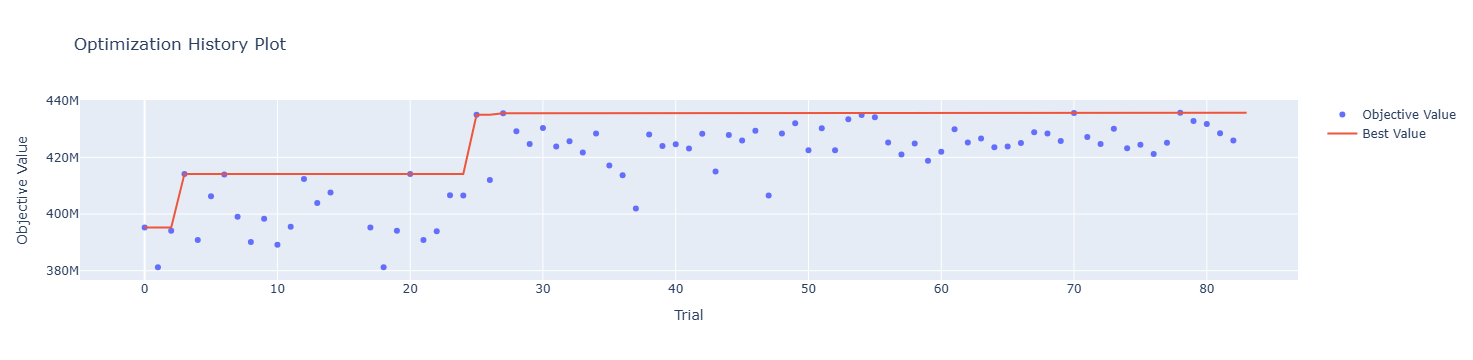

In [28]:
optuna.visualization.plot_optimization_history(study)

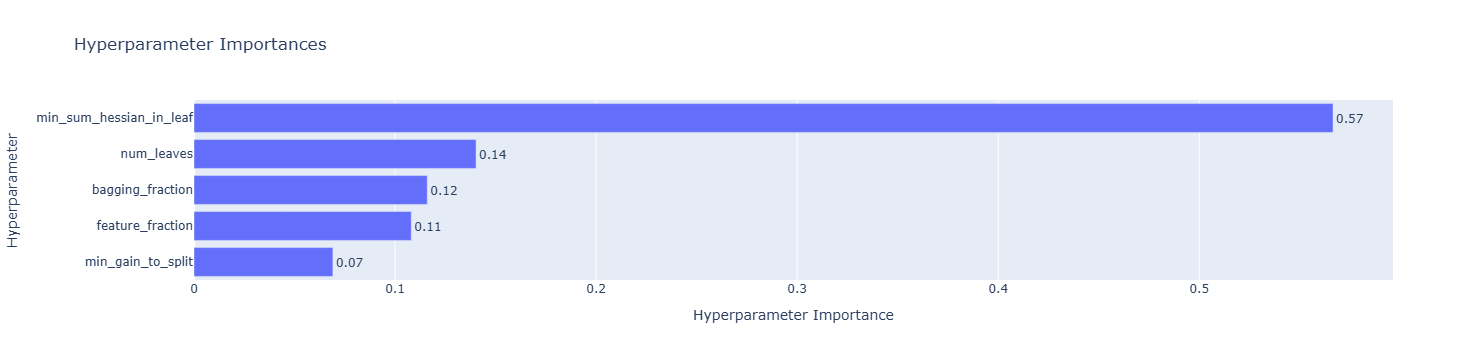

In [29]:
plot_param_importances(study)

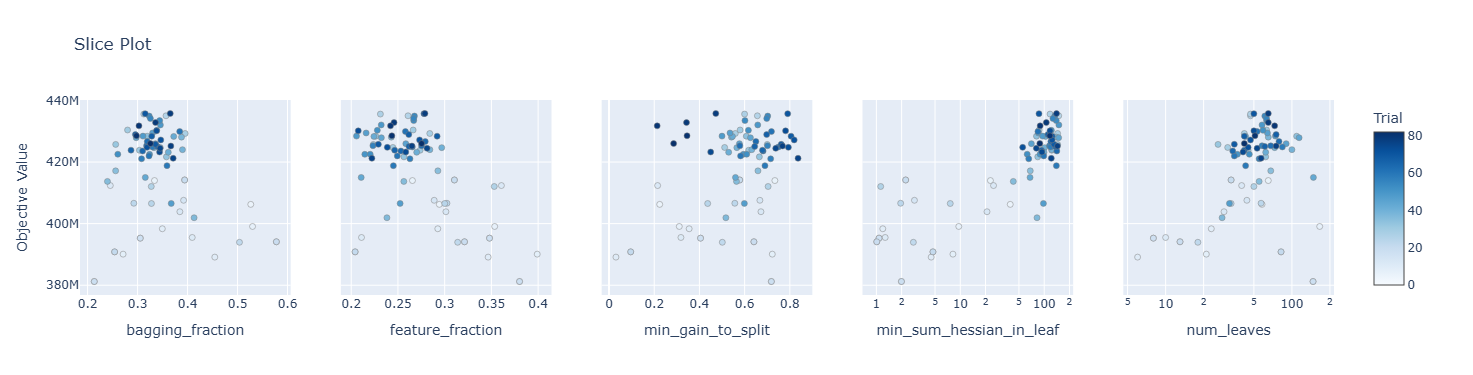

In [30]:
plot_slice(study)

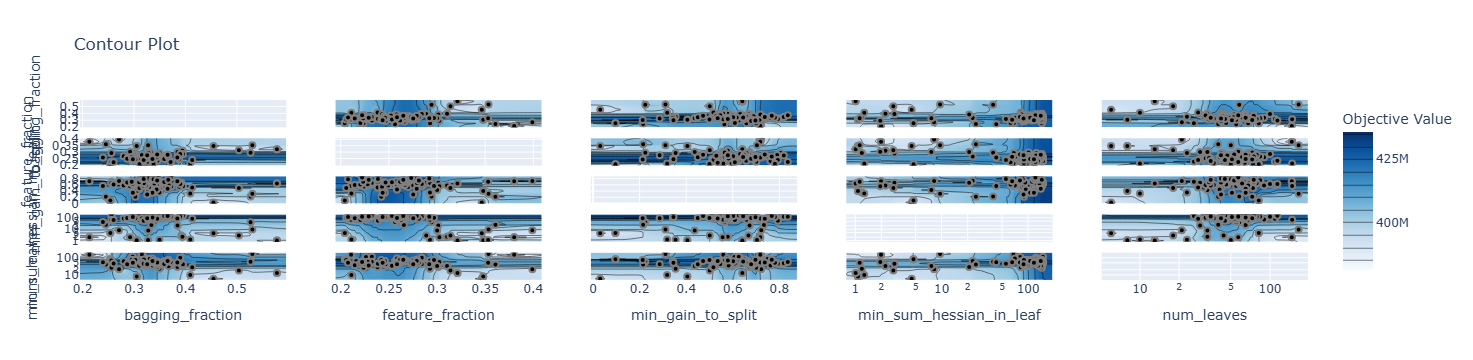

In [31]:
plot_contour(study)

,variable,gain,split
51,cpayroll_trx,1.593653e+06,122
106,ctrx_quarter,9.546065e+05,514
1409,m_payroll_media_hist_prev,7.550507e+05,183
159,c_payrroll,7.162979e+05,117
22,mcuentas_saldo,5.165619e+05,762
1410,m_payroll_min_hist_prev,4.545055e+05,165
52,mpayroll,3.769305e+05,350
570,mpayroll_media_hist_prev,3.699270e+05,180
18,mcaja_ahorro,3.199365e+05,703
11,mpasivos_margen,2.635361e+05,573


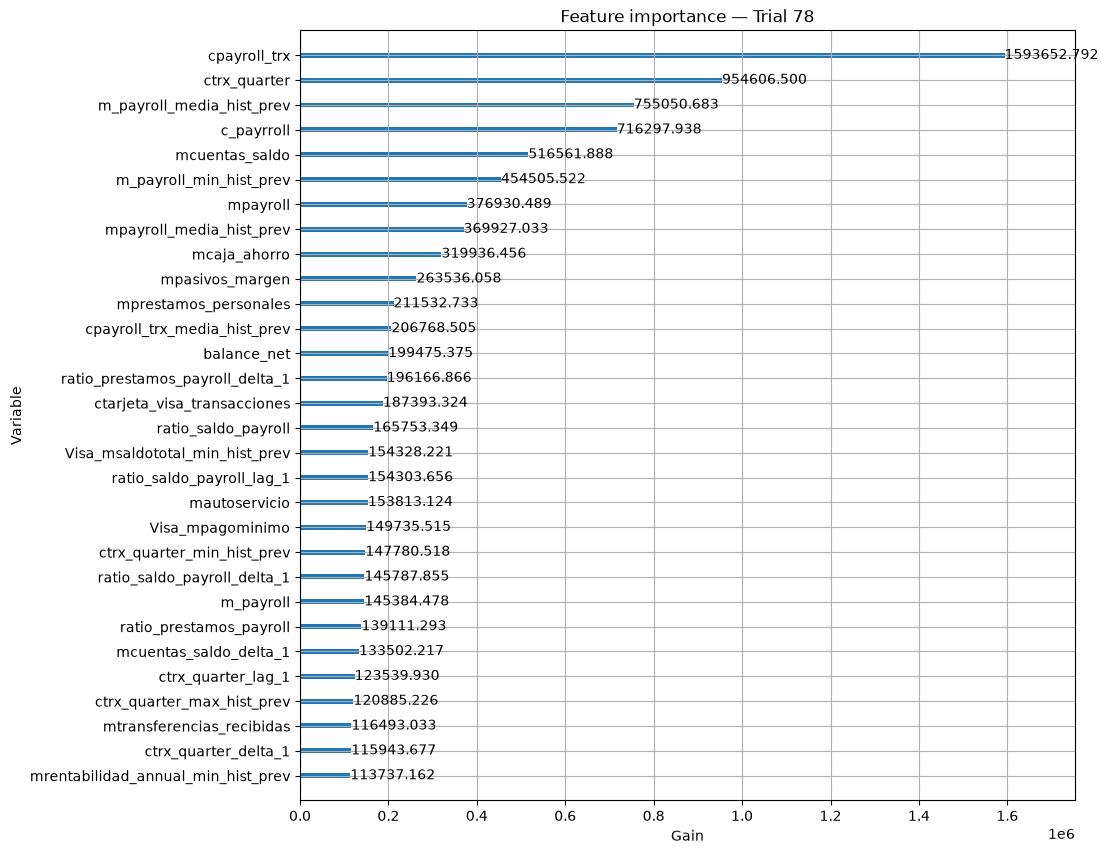

In [32]:
# Feature Importance
best_trial = study.best_trial
params = best_trial.user_attrs["params_completos"].copy()
params.update(study.best_params)

modelo_importancia = lgb.train(
    params,
    lgb.Dataset(X_train, label=y_train_binaria2, weight=w_train),
    num_boost_round=int(best_trial.user_attrs["best_iter"]),
)

importancias = pd.DataFrame({
    "variable": modelo_importancia.feature_name(),
    "gain": modelo_importancia.feature_importance(importance_type="gain"),
    "split": modelo_importancia.feature_importance(importance_type="split"),
}).sort_values("gain", ascending=False)

display(importancias.head(30))

lgb.plot_importance(
    modelo_importancia,
    importance_type="gain",
    max_num_features=30,
    figsize=(10, 10),
    title=f"Feature importance — Trial {best_trial.number}",
    xlabel="Gain",
    ylabel="Variable",
)
plt.show()

Probar dropeando las ultimas 700 columnas for feature importance

### 2) Revalidación temporal con SSS — preparación

Se seleccionan los diez mejores trials de Optuna. Cada repetición entrena sobre el **70 %**
del mes de origen, estratificando por las tres clases; el 30 % restante se descarta.
El mes siguiente se evalúa completo. Los modelos conservan sus parámetros y `best_iter`,
sin early stopping adicional. El dataset de entrenamiento se construye una vez por repetición. No se construyen datasets de validación.

In [37]:
# Selección de trials y definición de split y partición
from time import perf_counter

top_trials = sorted(
    [t for t in study.trials
     if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None],
    key=lambda t: t.value,
    reverse=True,
)[:10]

trials_por_numero = {
    t.number: t for t in study.trials
    if t.state == optuna.trial.TrialState.COMPLETE
}
columnas_modelo = X_train.columns.tolist()
n_splits_temporal = 5
fraccion_train_sss = 0.5


def ganancias_individuales(clases):
    return np.where(
        np.asarray(clases) == "BAJA+2", ganancia_acierto, -costo_estimulo
    ).astype(np.float64)


def mejor_ganancia_ordenada(ganancias):
    curva = np.r_[0.0, np.cumsum(ganancias)]
    corte = int(np.argmax(curva))
    return float(curva[corte]), corte


def resumen_ganancias(df):
    return (
        df.groupby("trial")
        .agg(
            ganancia_media=("ganancia", "mean"),
            ganancia_std=("ganancia", "std"),
            ganancia_p10=("ganancia", lambda x: x.quantile(0.10)),
            ganancia_p25=("ganancia", lambda x: x.quantile(0.25)),
            ganancia_min=("ganancia", "min"),
            ganancia_max=("ganancia", "max"),
            repeticiones=("ganancia", "size"),
        )
        .sort_values(["ganancia_media", "ganancia_std"], ascending=[False, True])
    )


def evaluar_backtest_sss(mes_origen, mes_destino, nombre):
    origen = data.loc[data["foto_mes"] == mes_origen]
    X_destino = data.loc[data["foto_mes"] == mes_destino, columnas_modelo]
    ganancias_destino = ganancias_individuales(
        data.loc[data["foto_mes"] == mes_destino, "clase_ternaria"]
    )
    sss = StratifiedShuffleSplit(
        n_splits=n_splits_temporal,
        train_size=fraccion_train_sss,
        random_state=semilla,
    )
    resultados = []
    for fold, (idx_train, _) in enumerate(
        sss.split(origen, origen["clase_ternaria"]), start=1
    ):
        inicio_fold = perf_counter()
        train_fold = origen.iloc[idx_train]
        ds_train = lgb.Dataset(
            train_fold.loc[:, columnas_modelo],
            label=train_fold["clase_binaria2"],
            weight=train_fold["clase_peso"],
            params=top_trials[0].user_attrs["params_completos"].copy(),
        )
        ds_train.construct()
        n_train = len(train_fold)
        del train_fold

        for trial in top_trials:
            inicio_trial = perf_counter()
            params_trial = trial.user_attrs["params_completos"].copy()
            rondas = int(trial.user_attrs["best_iter"])
            modelo = lgb.train(
                params_trial, ds_train,
                num_boost_round=rondas, keep_training_booster=True,
            )
            pred = modelo.predict(X_destino, num_iteration=rondas)
            orden = np.argsort(-pred, kind="stable")
            ganancia, corte = mejor_ganancia_ordenada(ganancias_destino[orden])
            resultados.append({
                "trial": trial.number, "fold": fold, "backtest": nombre,
                "mes_train": mes_origen, "mes_valid": mes_destino,
                "best_iter": rondas, "n_train": n_train,
                "n_valid": len(X_destino), "ganancia": ganancia,
                "mejor_corte": corte,
            })
            del modelo, pred, orden
            print(
                f"{nombre} | Repetición {fold}/{n_splits_temporal} | "
                f"Trial {trial.number} | Ganancia: ${ganancia:,.0f} | "
                f"{(perf_counter() - inicio_trial) / 60:.1f} min",
                flush=True,
            )

        del ds_train
        print(
            f"{nombre} | Repetición {fold}/{n_splits_temporal} completada | "
            f"{(perf_counter() - inicio_fold) / 60:.1f} min",
            flush=True,
        )
    detalle = pd.DataFrame(resultados)
    return detalle, resumen_ganancias(detalle)

#### 2.A Abril -> Mayo - Criterio Principal
Los cinco primeros de `resumen_A` son la propuesta
inicial para el paso 3 (mayor media; menor desvío como desempate).

In [38]:
df_sss_A, resumen_A = evaluar_backtest_sss(202104, 202105, "A: abril → mayo")
display(resumen_A.round(2))
display(df_sss_A)

A: abril → mayo | Repetición 1/5 | Trial 78 | Ganancia: $255,695,000 | 2.8 min
A: abril → mayo | Repetición 1/5 | Trial 70 | Ganancia: $255,970,000 | 3.6 min
A: abril → mayo | Repetición 1/5 | Trial 27 | Ganancia: $252,972,500 | 2.9 min
A: abril → mayo | Repetición 1/5 | Trial 25 | Ganancia: $253,577,500 | 2.4 min
A: abril → mayo | Repetición 1/5 | Trial 54 | Ganancia: $253,632,500 | 2.7 min
A: abril → mayo | Repetición 1/5 | Trial 55 | Ganancia: $265,265,000 | 7.1 min
A: abril → mayo | Repetición 1/5 | Trial 53 | Ganancia: $257,757,500 | 2.2 min
A: abril → mayo | Repetición 1/5 | Trial 79 | Ganancia: $252,532,500 | 2.0 min
A: abril → mayo | Repetición 1/5 | Trial 49 | Ganancia: $248,765,000 | 2.3 min
A: abril → mayo | Repetición 1/5 | Trial 80 | Ganancia: $254,127,500 | 2.4 min
A: abril → mayo | Repetición 1/5 completada | 30.6 min
A: abril → mayo | Repetición 2/5 | Trial 78 | Ganancia: $250,085,000 | 2.9 min
A: abril → mayo | Repetición 2/5 | Trial 70 | Ganancia: $242,770,000 | 3.7 m

,ganancia_media,ganancia_std,ganancia_p10,ganancia_p25,ganancia_min,ganancia_max,repeticiones
trial,,,,,,,
55,254309000.0,6591934.13,249353500.0,252175000.0,247472500.0,265265000.0,5
78,253797500.0,4101604.49,249969500.0,250085000.0,249892500.0,259682500.0,5
53,253000000.0,6585690.22,246081000.0,249975000.0,243485000.0,260122500.0,5
25,252411500.0,4276077.57,248545000.0,251102500.0,246840000.0,258637500.0,5
80,251938500.0,3951138.52,248193000.0,248490000.0,247995000.0,257427500.0,5
49,251883500.0,3723311.11,249084000.0,249562500.0,248765000.0,257950000.0,5
27,251828500.0,6099131.75,245927000.0,252147500.0,241780000.0,258307500.0,5
70,251460000.0,5277564.54,245960000.0,250745000.0,242770000.0,255970000.0,5
54,251174000.0,4352373.49,246290000.0,248352500.0,244915000.0,255062500.0,5


,trial,fold,backtest,mes_train,mes_valid,best_iter,n_train,n_valid,ganancia,mejor_corte
0,78,1,A: abril → mayo,202104,202105,3194,81642,163768,255695000.0,10222
1,70,1,A: abril → mayo,202104,202105,4069,81642,163768,255970000.0,10732
2,27,1,A: abril → mayo,202104,202105,3681,81642,163768,252972500.0,8601
3,25,1,A: abril → mayo,202104,202105,2780,81642,163768,253577500.0,11179
4,54,1,A: abril → mayo,202104,202105,2643,81642,163768,253632500.0,9537
5,55,1,A: abril → mayo,202104,202105,1993,81642,163768,265265000.0,10554
6,53,1,A: abril → mayo,202104,202105,2534,81642,163768,257757500.0,8387
7,79,1,A: abril → mayo,202104,202105,2317,81642,163768,252532500.0,7057
8,49,1,A: abril → mayo,202104,202105,2848,81642,163768,248765000.0,7794
9,80,1,A: abril → mayo,202104,202105,2826,81642,163768,254127500.0,10319


#### 2.B Mayo -> Junio - Diagnóstico Complementario
Este bloque puede ejecutarse independientemente de 2A, después de la preparación común.
No modifica la selección de candidatos basada en A.

In [39]:
df_sss_B, resumen_B = evaluar_backtest_sss(202105, 202106, "B: mayo → junio")
display(resumen_B.round(2))
display(df_sss_B)

B: mayo → junio | Repetición 1/5 | Trial 78 | Ganancia: $428,532,500 | 3.5 min
B: mayo → junio | Repetición 1/5 | Trial 70 | Ganancia: $434,142,500 | 4.4 min
B: mayo → junio | Repetición 1/5 | Trial 27 | Ganancia: $428,752,500 | 3.6 min
B: mayo → junio | Repetición 1/5 | Trial 25 | Ganancia: $432,850,000 | 2.9 min
B: mayo → junio | Repetición 1/5 | Trial 54 | Ganancia: $438,267,500 | 2.8 min
B: mayo → junio | Repetición 1/5 | Trial 55 | Ganancia: $431,117,500 | 2.2 min
B: mayo → junio | Repetición 1/5 | Trial 53 | Ganancia: $441,017,500 | 2.7 min
B: mayo → junio | Repetición 1/5 | Trial 79 | Ganancia: $436,012,500 | 2.4 min
B: mayo → junio | Repetición 1/5 | Trial 49 | Ganancia: $436,425,000 | 2.8 min
B: mayo → junio | Repetición 1/5 | Trial 80 | Ganancia: $432,850,000 | 2.9 min
B: mayo → junio | Repetición 1/5 completada | 30.3 min
B: mayo → junio | Repetición 2/5 | Trial 78 | Ganancia: $421,850,000 | 3.5 min
B: mayo → junio | Repetición 2/5 | Trial 70 | Ganancia: $416,872,500 | 4.4 m

,ganancia_media,ganancia_std,ganancia_p10,ganancia_p25,ganancia_min,ganancia_max,repeticiones
trial,,,,,,,
54,414689000.0,18222621.38,398084500.0,399190000.0,397347500.0,438267500.0,5
53,414359000.0,16639483.97,400147000.0,401170000.0,399465000.0,441017500.0,5
49,412995000.0,16700335.89,397556500.0,402077500.0,394542500.0,436425000.0,5
25,412159000.0,14146466.17,398722500.0,404332500.0,394982500.0,432850000.0,5
79,411906000.0,17408397.09,394955000.0,400565000.0,391215000.0,436012500.0,5
78,410927000.0,13350767.11,399899500.0,401087500.0,399107500.0,428532500.0,5
27,408848000.0,16273894.97,394289500.0,394817500.0,393937500.0,428752500.0,5
70,408666500.0,18379863.18,390566000.0,396522500.0,386595000.0,434142500.0,5
55,408342000.0,14665074.73,395791000.0,399190000.0,393525000.0,431117500.0,5


,trial,fold,backtest,mes_train,mes_valid,best_iter,n_train,n_valid,ganancia,mejor_corte
0,78,1,B: mayo → junio,202105,202106,3194,81884,164114,428532500.0,11497
1,70,1,B: mayo → junio,202105,202106,4069,81884,164114,434142500.0,10893
2,27,1,B: mayo → junio,202105,202106,3681,81884,164114,428752500.0,13329
3,25,1,B: mayo → junio,202105,202106,2780,81884,164114,432850000.0,12220
4,54,1,B: mayo → junio,202105,202106,2643,81884,164114,438267500.0,12743
5,55,1,B: mayo → junio,202105,202106,1993,81884,164114,431117500.0,14323
6,53,1,B: mayo → junio,202105,202106,2534,81884,164114,441017500.0,12083
7,79,1,B: mayo → junio,202105,202106,2317,81884,164114,436012500.0,12625
8,49,1,B: mayo → junio,202105,202106,2848,81884,164114,436425000.0,12690
9,80,1,B: mayo → junio,202105,202106,2826,81884,164114,432850000.0,11500


,ganancia_media_A,ganancia_std_A,ganancia_p10_A,ganancia_p25_A,ganancia_min_A,ganancia_max_A,repeticiones_A,ganancia_media_B,ganancia_std_B,ganancia_p10_B,ganancia_p25_B,ganancia_min_B,ganancia_max_B,repeticiones_B
trial,,,,,,,,,,,,,,
55,254309000.0,6591934.13,249353500.0,252175000.0,247472500.0,265265000.0,5,408342000.0,14665074.73,395791000.0,399190000.0,393525000.0,431117500.0,5
78,253797500.0,4101604.49,249969500.0,250085000.0,249892500.0,259682500.0,5,410927000.0,13350767.11,399899500.0,401087500.0,399107500.0,428532500.0,5
53,253000000.0,6585690.22,246081000.0,249975000.0,243485000.0,260122500.0,5,414359000.0,16639483.97,400147000.0,401170000.0,399465000.0,441017500.0,5
25,252411500.0,4276077.57,248545000.0,251102500.0,246840000.0,258637500.0,5,412159000.0,14146466.17,398722500.0,404332500.0,394982500.0,432850000.0,5
80,251938500.0,3951138.52,248193000.0,248490000.0,247995000.0,257427500.0,5,408292500.0,17817793.07,392843000.0,394047500.0,392040000.0,432850000.0,5
49,251883500.0,3723311.11,249084000.0,249562500.0,248765000.0,257950000.0,5,412995000.0,16700335.89,397556500.0,402077500.0,394542500.0,436425000.0,5
27,251828500.0,6099131.75,245927000.0,252147500.0,241780000.0,258307500.0,5,408848000.0,16273894.97,394289500.0,394817500.0,393937500.0,428752500.0,5
70,251460000.0,5277564.54,245960000.0,250745000.0,242770000.0,255970000.0,5,408666500.0,18379863.18,390566000.0,396522500.0,386595000.0,434142500.0,5
54,251174000.0,4352373.49,246290000.0,248352500.0,244915000.0,255062500.0,5,414689000.0,18222621.38,398084500.0,399190000.0,397347500.0,438267500.0,5


/tmp/ipykernel_7070/2069164804.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(valores, vert=False, showmeans=True)
/tmp/ipykernel_7070/2069164804.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(valores, vert=False, showmeans=True)


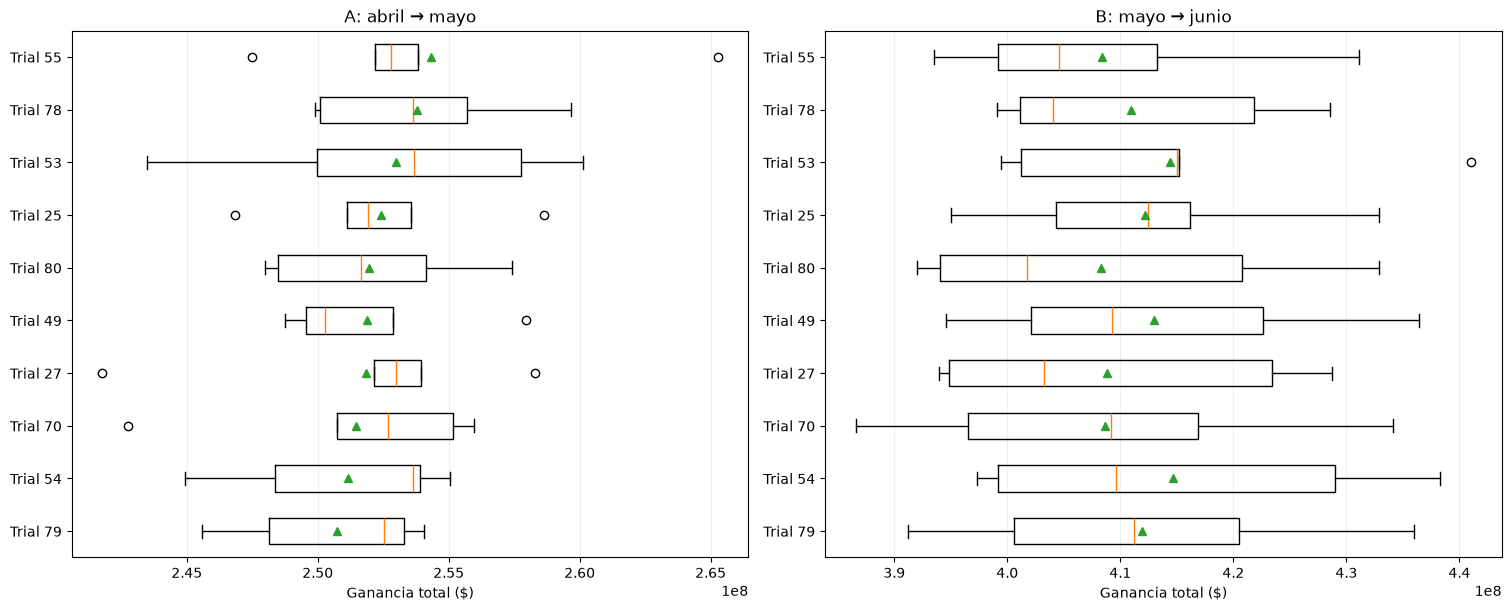

In [40]:
# Comparación: conservar el orden de preferencia del backtest A.
comparacion_temporal = resumen_A.add_suffix("_A").join(
    resumen_B.add_suffix("_B")
)
display(comparacion_temporal.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
orden_trials = resumen_A.index.tolist()
for ax, detalle, titulo in [
    (axes[0], df_sss_A, "A: abril → mayo"),
    (axes[1], df_sss_B, "B: mayo → junio"),
]:
    valores = [detalle.loc[detalle["trial"] == t, "ganancia"] for t in orden_trials]
    ax.boxplot(valores, vert=False, showmeans=True)
    ax.set_yticks(np.arange(1, len(orden_trials) + 1))
    ax.set_yticklabels([f"Trial {t}" for t in orden_trials])
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel("Ganancia total ($)")
    ax.grid(axis="x", alpha=0.2)
plt.show()

### 3. Pseudo público/privado en junio
Editar `trials_evaluar` para indicar los números de trials deseados. Por defecto se proponen
los cinco mejores de A. Cada candidato se entrena **una vez** con abril + mayo y predice junio.
Las particiones posteriores reutilizan esas predicciones y los rankings precalculados.

No se estratifica junio, mismas particiones
para todos los trials. La métrica mantiene la convención anterior: máximo de la curva de ganancia
en cada subconjunto, incluyendo cero envíos. Por tanto, es un diagnóstico de estabilidad del
ranking de configuraciones con cortes óptimos retrospectivos; no simula un envío con corte fijo
ni la transferencia del corte público al privado. Las ganancias son totales de cada subconjunto.

Para cada partición `s`, se elige `t_publico = argmax_t G_publico(s,t)` y se calcula:

`regret_seleccion(s) = max_t G_privado(s,t) - G_privado(s,t_publico)`.

Las tablas por candidato incluyen además el regret contra el mejor candidato de su propio tablero.
Los empates de ranking se resuelven por número de trial ascendente. Las frecuencias top-1/top-3
son proporciones entre 0 y 1. El pseudo privado reutiliza junio, ya visto por Optuna;
sus resultados no son una estimación independiente de agosto.

In [41]:
# Lista editable: reemplazar por los números de trials que quieras evaluar.
trials_evaluar = resumen_A.head(5).index.astype(int).tolist()
# trials_evaluar = [55, 78, 53, 25, 80]

semilla_pp = semilla
print("Trials para público/privado:", trials_evaluar)

Trials para público/privado: [55, 78, 53, 25, 80]


In [42]:
# Entrenar solo una vez por candidato; no repetir al pasar de 50 a 500 splits.
train_pp = data.loc[data["foto_mes"].isin([202104, 202105])]
X_train_pp = train_pp.loc[:, columnas_modelo]
mascara_junio = data["foto_mes"] == 202106
X_junio = data.loc[mascara_junio, columnas_modelo]
clases_junio = data.loc[mascara_junio, "clase_ternaria"].to_numpy()
ganancias_junio = ganancias_individuales(clases_junio)

params_dataset_pp = trials_por_numero[trials_evaluar[0]].user_attrs["params_completos"].copy()
params_dataset_pp["seed"] = semilla_pp
ds_train_pp = lgb.Dataset(
    X_train_pp,
    label=train_pp["clase_binaria2"],
    weight=train_pp["clase_peso"],
    params=params_dataset_pp,
)
ds_train_pp.construct()
del train_pp, X_train_pp

predicciones_junio = {}
ordenes_junio = {}
ganancias_ordenadas_junio = {}
for numero_trial in trials_evaluar:
    inicio = perf_counter()
    trial = trials_por_numero[numero_trial]
    params_pp = trial.user_attrs["params_completos"].copy()
    params_pp["seed"] = semilla_pp
    rondas = int(trial.user_attrs["best_iter"])
    modelo = lgb.train(
        params_pp, ds_train_pp,
        num_boost_round=rondas, keep_training_booster=True,
    )
    pred = modelo.predict(X_junio, num_iteration=rondas)
    orden = np.argsort(-pred, kind="stable")
    predicciones_junio[numero_trial] = pred
    ordenes_junio[numero_trial] = orden
    ganancias_ordenadas_junio[numero_trial] = ganancias_junio[orden]
    del modelo
    print(
        f"Trial {numero_trial}: predicciones de junio guardadas | "
        f"{(perf_counter() - inicio) / 60:.1f} min", flush=True,
    )
del ds_train_pp

Trial 55: predicciones de junio guardadas | 8.7 min
Trial 78: predicciones de junio guardadas | 14.5 min
Trial 53: predicciones de junio guardadas | 11.1 min
Trial 25: predicciones de junio guardadas | 11.8 min
Trial 80: predicciones de junio guardadas | 11.8 min


In [45]:
# Cambiar solamente este valor a 500 y volver a ejecutar desde esta celda.
from sklearn.model_selection import ShuffleSplit

n_splits_pp = 1000

sss_pp = ShuffleSplit(
    n_splits=n_splits_pp,
    test_size=0.75,  # 25 % público y 75 % privado.
    random_state=semilla,
)

resultados_pp = []
inicio_pp = perf_counter()

for split, (idx_public, idx_private) in enumerate(
    sss_pp.split(X_junio), start=1
):
    es_publico = np.zeros(len(X_junio), dtype=bool)
    es_publico[idx_public] = True
    for numero_trial in trials_evaluar:
        # Filtrar un ranking ya ordenado evita ordenar de nuevo en cada split.
        mascara_ordenada = es_publico[ordenes_junio[numero_trial]]
        ganancias_ordenadas = ganancias_ordenadas_junio[numero_trial]
        gain_public, corte_public = mejor_ganancia_ordenada(
            ganancias_ordenadas[mascara_ordenada]
        )
        gain_private, corte_private = mejor_ganancia_ordenada(
            ganancias_ordenadas[~mascara_ordenada]
        )
        resultados_pp.append({
            "split": split, "trial": numero_trial,
            "gain_public": gain_public, "gain_private": gain_private,
            "corte_public": corte_public, "corte_private": corte_private,
            "n_public": len(idx_public), "n_private": len(idx_private),
        })
    # print(f"Público/privado: partición {split}/{n_splits_pp} completada", flush=True)

df_pp = pd.DataFrame(resultados_pp).sort_values(["split", "trial"])
for tablero in ["public", "private"]:
    grupo = df_pp.groupby("split")[f"gain_{tablero}"]
    df_pp[f"ranking_{tablero}"] = grupo.rank(ascending=False, method="first")
    df_pp[f"top1_{tablero}"] = df_pp[f"ranking_{tablero}"].eq(1)
    df_pp[f"top3_{tablero}"] = df_pp[f"ranking_{tablero}"].le(3)
    df_pp[f"regret_{tablero}"] = grupo.transform("max") - df_pp[f"gain_{tablero}"]


def resumir_tablero(tablero):
    return (
        df_pp.groupby("trial")
        .agg(
            ganancia_media=(f"gain_{tablero}", "mean"),
            ganancia_std=(f"gain_{tablero}", "std"),
            ganancia_p10=(f"gain_{tablero}", lambda x: x.quantile(0.10)),
            ganancia_p25=(f"gain_{tablero}", lambda x: x.quantile(0.25)),
            ranking_medio=(f"ranking_{tablero}", "mean"),
            frecuencia_top1=(f"top1_{tablero}", "mean"),
            frecuencia_top3=(f"top3_{tablero}", "mean"),
            regret_medio=(f"regret_{tablero}", "mean"),
            regret_p90=(f"regret_{tablero}", lambda x: x.quantile(0.90)),
        )
        .sort_values(["ranking_medio", "ganancia_media"], ascending=[True, False])
    )


resumen_public = resumir_tablero("public")
resumen_private = resumir_tablero("private")
print("PÚBLICO — ganancia total del 25 %")
display(resumen_public.round(2))
print("PRIVADO — ganancia total del 75 %")
display(resumen_private.round(2))

# Regret de CONFIAR EN EL PÚBLICO: seguir al ganador público al tablero privado.
df_regret = df_pp.loc[df_pp["top1_public"], [
    "split", "trial", "gain_public", "gain_private", "ranking_private", "regret_private"
]].rename(columns={
    "trial": "trial_elegido_publico",
    "gain_private": "ganancia_privada_elegido",
    "regret_private": "regret_seleccion",
}).copy()
df_regret["mejor_ganancia_privada"] = (
    df_regret["ganancia_privada_elegido"] + df_regret["regret_seleccion"]
)
resumen_regret = df_regret[["regret_seleccion", "ganancia_privada_elegido"]].agg(
    ["mean", "std", "min", "max"]
)
resumen_regret.loc["P10"] = df_regret[["regret_seleccion", "ganancia_privada_elegido"]].quantile(0.10)
resumen_regret.loc["P25"] = df_regret[["regret_seleccion", "ganancia_privada_elegido"]].quantile(0.25)
resumen_regret.loc["P90"] = df_regret[["regret_seleccion", "ganancia_privada_elegido"]].quantile(0.90)

print("REGRET — pérdida privada por elegir el ganador público")
display(resumen_regret.round(2))
display(df_regret)
print(f"Frecuencia de regret positivo: {df_regret['regret_seleccion'].gt(0).mean():.1%}")
print(f"Tiempo de particiones y resúmenes: {perf_counter() - inicio_pp:.1f} s")

PÚBLICO — ganancia total del 25 %


,ganancia_media,ganancia_std,ganancia_p10,ganancia_p25,ranking_medio,frecuencia_top1,frecuencia_top3,regret_medio,regret_p90
trial,,,,,,,,,
78,110628045.0,12198187.70,95425000.0,102093750.0,2.29,0.36,0.81,1243742.5,3247750.0
25,109975360.0,12177658.74,94930000.0,101530000.0,2.74,0.24,0.69,1896427.5,4235000.0
55,109395742.5,12202839.88,94127000.0,100980000.0,3.21,0.16,0.53,2476045.0,5225000.0
53,109336122.5,12294381.58,93992250.0,101117500.0,3.27,0.13,0.52,2535665.0,5087500.0
80,108944192.5,11987882.61,93904250.0,100457500.0,3.49,0.12,0.45,2927595.0,5912500.0


PRIVADO — ganancia total del 75 %


,ganancia_media,ganancia_std,ganancia_p10,ganancia_p25,ranking_medio,frecuencia_top1,frecuencia_top3,regret_medio,regret_p90
trial,,,,,,,,,
78,327626062.5,12305556.64,311866500.0,319041250.0,1.95,0.47,0.89,1127335.0,3492500.0
25,326581832.5,12386822.22,310909500.0,318312500.0,2.60,0.25,0.72,2171565.0,5117750.0
55,325960580.0,12254767.08,309757250.0,317686875.0,2.99,0.17,0.62,2792817.5,5887750.0
53,325364407.5,12519916.27,309130250.0,316353125.0,3.38,0.07,0.50,3388990.0,6330500.0
80,324124707.5,12208213.88,308602250.0,315693125.0,4.07,0.04,0.27,4628690.0,7947500.0


REGRET — pérdida privada por elegir el ganador público


,regret_seleccion,ganancia_privada_elegido
mean,4003010.00,3.247504e+08
std,2757494.88,1.248536e+07
min,0.00,2.849275e+08
max,12705000.00,3.629450e+08
P10,0.00,3.084785e+08
P25,1622500.00,3.161950e+08
P90,7672500.00,3.406068e+08


,split,trial_elegido_publico,gain_public,ganancia_privada_elegido,ranking_private,regret_seleccion,mejor_ganancia_privada
1,1,78,114070000.0,323235000.0,4.0,3905000.0,327140000.0
9,2,80,109587500.0,322437500.0,5.0,8360000.0,330797500.0
12,3,53,87367500.0,346087500.0,5.0,8552500.0,354640000.0
15,4,55,128590000.0,305635000.0,5.0,5555000.0,311190000.0
24,5,80,112667500.0,321090000.0,5.0,6132500.0,327222500.0
...,...,...,...,...,...,...,...
4976,996,78,102217500.0,335390000.0,3.0,1567500.0,336957500.0
4980,997,55,110825000.0,324665000.0,5.0,3657500.0,328322500.0
4989,998,80,114070000.0,319632500.0,5.0,6627500.0,326260000.0
4991,999,78,125317500.0,313335000.0,3.0,550000.0,313885000.0


Frecuencia de regret positivo: 89.4%
Tiempo de particiones y resúmenes: 18.9 s


### 4. Elección y ajustes manuales del entrenamiento definitivo
La elección por defecto conserva la prioridad de A entre los trials de la lista evaluada.
Las tablas público/privado sirven para revisar esa elección; no se selecciona automáticamente
por el pseudo privado. Editar `trial_elegido` o `trials_finales` para otra decisión.

Los factores comienzan en 1.0: los aumentos son manuales, no proporcionales automáticamente
al tamaño de los datos. `ajustes_params_finales` permite cambiar otros parámetros de LightGBM.
Las rondas se modifican en su variable específica. Los ajustes y el ensamble final no están
revalidados por los resultados previos. El corte de exportación se mantiene manual.

In [55]:
# trial_elegido = int(resumen_A.loc[resumen_A.index.isin(trials_evaluar)].index[0])
trial_elegido = 78 #trial individual para la curva de referencia posterior

meses_train_final = [202104, 202105, 202106]
trials_finales = [78, 25]
semillas_finales = [1977, 1978, 2000, 2001, 2003, 2007]

# Alternativa: dos o tres configuraciones, cada una con seis semillas.
# trials_finales = resumen_A.loc[resumen_A.index.isin(trials_evaluar)].head(3).index.tolist()
# semillas_finales = [12, 2000, 2001, 2003, 2007, 2011]

factor_hessiano_final = 1.5    # Ejemplo: 1.25 aumenta el mínimo un 25 %. En version Abril-Junio utilice 1.5
factor_rondas_final = 1.1      # Ejemplo: 1.20 aumenta las rondas un 20 %. En version Abril-Junio utilice 1.1
factor_gain_final = 1.5   #En version Abril-Junio utilice 1.5
num_boost_round_final = None  # Un entero fija las rondas para todos los trials.
ajustes_params_finales = {
    # "min_data_in_leaf": 500,
    # "min_gain_to_split": 0.7,
    # "learning_rate": 0.005,
    # "min_sum_hessian_in_leaf": 100.0,  # Valor absoluto; prevalece sobre el factor.
}

configuraciones_finales = []
for numero_trial in trials_finales:
    trial = trials_por_numero[numero_trial]
    params_finales = trial.user_attrs["params_completos"].copy()
    params_finales["min_sum_hessian_in_leaf"] *= factor_hessiano_final
    params_finales["min_gain_to_split"] *= factor_gain_final
    params_finales.update(ajustes_params_finales)
    rondas = (
        int(round(trial.user_attrs["best_iter"] * factor_rondas_final))
        if num_boost_round_final is None else int(num_boost_round_final)
    )
    configuraciones_finales.append((numero_trial, params_finales, rondas))

display(pd.DataFrame([
    {"trial": numero, "rondas": rondas, **params}
    for numero, params, rondas in configuraciones_finales
]))
print("Meses finales:", meses_train_final)
print("Semillas:", semillas_finales)
print("Cantidad de modelos:", len(trials_finales) * len(semillas_finales))

,trial,rondas,objective,metric,boosting_type,first_metric_only,boost_from_average,feature_pre_filter,max_bin,num_leaves,...,min_data_in_leaf,feature_fraction,bagging_fraction,bagging_freq,min_gain_to_split,seed,verbose,feature_fraction_bynode,min_sum_hessian_in_leaf,is_unbalance
0,78,3673,binary,custom,gbdt,True,True,False,31,65,...,0,0.278879,0.365376,1,0.944814,12,-1,0.2,280.417484,True
1,25,3197,binary,custom,gbdt,True,True,False,31,47,...,0,0.260794,0.356868,1,1.312737,12,-1,0.2,297.902795,True


Meses finales: [202103, 202104, 202105, 202106]
Semillas: [1977, 1978, 2000, 2001, 2003, 2007]
Cantidad de modelos: 12


#### Curva de referencia del trial elegido
Se reutilizan las predicciones de junio obtenidas entrenando con abril + mayo.
Esta curva no corresponde al ensamble final ni evalúa un modelo entrenado con junio.
El máximo orienta la elección manual del corte; no sustituye la validación del ensamble.

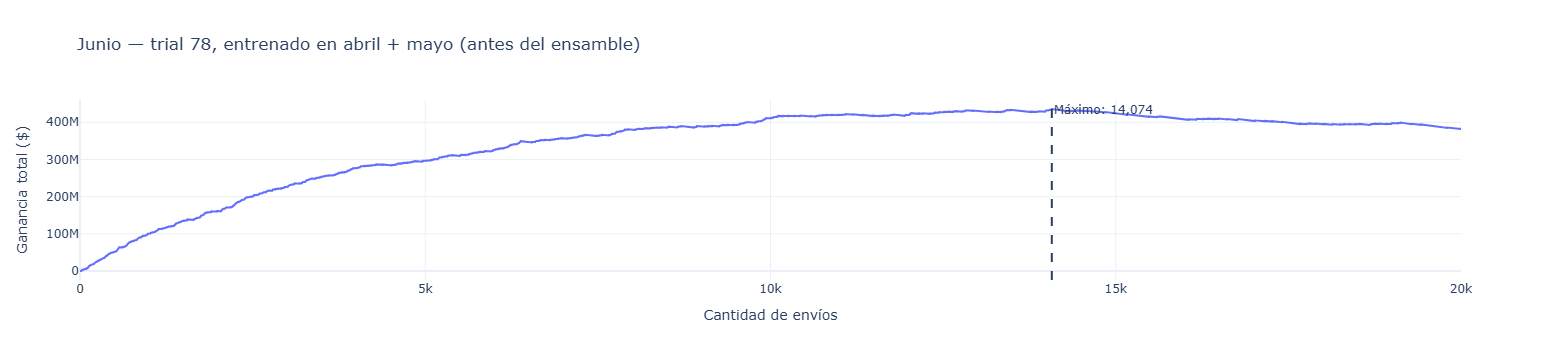

Corte de referencia: 14,074 | Ganancia: $435,765,000


In [48]:
import plotly.graph_objects as go

pred_val = predicciones_junio[trial_elegido]
orden = ordenes_junio[trial_elegido]
ganancia_acumulada = np.r_[0.0, np.cumsum(ganancias_junio[orden])]
mejor_corte = int(np.argmax(ganancia_acumulada))
mejor_ganancia = float(ganancia_acumulada[mejor_corte])
limite = min(len(pred_val), max(20_000, int(np.ceil(mejor_corte * 1.10))))

fig = go.Figure(go.Scatter(
    x=np.arange(limite + 1), y=ganancia_acumulada[:limite + 1],
    mode="lines", name="Ganancia acumulada",
))
fig.add_vline(x=mejor_corte, line_dash="dash", annotation_text=f"Máximo: {mejor_corte:,}")
fig.update_layout(
    title=f"Junio — trial {trial_elegido}, entrenado en abril + mayo (antes del ensamble)",
    xaxis_title="Cantidad de envíos", yaxis_title="Ganancia total ($)",
    template="plotly_white",
)
fig.show()
print(f"Corte de referencia: {mejor_corte:,} | Ganancia: ${mejor_ganancia:,.0f}")

### 5. Ensamble final y predicción de agosto

Se promedian los scores de todos los modelos con el mismo peso. Cada modelo se guarda en
`modelos_path` y se libera después de predecir agosto; no se mantienen todos los árboles en RAM.
Se conserva la ruta de agosto que estaba comentada en el borrador y se activa su lectura.
El manifiesto guarda configuración, semillas, rondas y archivos para reconstruir el ensamble.

In [ ]:
import json

train_data_final = data.loc[data["foto_mes"].isin(meses_train_final)]
X_train_final = train_data_final.loc[:, columnas_modelo]
y_train_final = train_data_final["clase_binaria2"]
w_train_final = train_data_final["clase_peso"]

mes_prediccion = 202108
datos_agosto = pd.read_parquet(
    Path(dataset_path) / "competencia_01_fe_v3_Ago.parquet"
)
datos_agosto = datos_agosto.loc[datos_agosto["foto_mes"] == mes_prediccion]
# Seleccionar las variables de entrenamiento también excluye ccajas_depositos de agosto.
X_agosto = datos_agosto.loc[:, columnas_modelo]

Path(modelos_path).mkdir(parents=True, exist_ok=True)
periodo_final = "_".join(str(mes) for mes in meses_train_final)
trials_texto = "_".join(str(t) for t in trials_finales)
ejecucion_final = datetime.now(timezone(timedelta(hours=-3))).strftime("%Y%m%d_%H%M%S_%f")
nombre_ensamble = (
    f"v1_4_ensamble_t{trials_texto}_{periodo_final}"
)

proba_agosto = np.zeros(len(X_agosto), dtype=np.float64)
registros_modelos = []
total_modelos = len(configuraciones_finales) * len(semillas_finales)

for numero_trial, params_base, rondas in configuraciones_finales:
    for seed in semillas_finales:
        inicio = perf_counter()
        params_modelo = params_base.copy()
        params_modelo["seed"] = int(seed)

        # Dataset propio: permite variar semillas de discretización y parámetros manuales.
        dataset_final = lgb.Dataset(
            X_train_final, label=y_train_final, weight=w_train_final,
            params=params_modelo,
        )
        model_final = lgb.train(
            params_modelo, dataset_final,
            num_boost_round=rondas, keep_training_booster=True,
        )
        proba_agosto += model_final.predict(X_agosto, num_iteration=rondas)
        archivo_modelo = Path(modelos_path) / (
            f"{nombre_ensamble}_trial{numero_trial}_seed{seed}.txt" #nombre de archivo
        )
        model_final.save_model(str(archivo_modelo))
        registros_modelos.append({
            "trial": int(numero_trial), "seed": int(seed),
            "rondas_solicitadas": rondas,
            "arboles_entrenados": model_final.current_iteration(),
            "peso_ensamble": 1 / total_modelos,
            "archivo": str(archivo_modelo), "params": params_modelo,
        })
        del model_final, dataset_final
        print(
            f"Modelo {len(registros_modelos)}/{total_modelos} | "
            f"Trial {numero_trial} | Semilla {seed} | "
            f"{(perf_counter() - inicio) / 60:.1f} min", flush=True,
        )

proba_agosto /= total_modelos
ranking_agosto = pd.DataFrame({
    "numero_de_cliente": datos_agosto["numero_de_cliente"].to_numpy(),
    "probabilidad": proba_agosto,
}).sort_values("probabilidad", ascending=False, kind="stable").reset_index(drop=True)

archivo_manifiesto = Path(modelos_path) / f"{nombre_ensamble}.json"
archivo_manifiesto.write_text(
    json.dumps({
        "estudio": study.study_name,
        "meses_train_final": meses_train_final,
        "columnas": columnas_modelo,
        "modelos": registros_modelos,
    }, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
display(pd.DataFrame(registros_modelos).drop(columns="params"))
print(f"Manifiesto: {archivo_manifiesto}")
print(f"Clientes de agosto: {len(ranking_agosto):,}")

Modelo 1/12 | Trial 78 | Semilla 1977 | 35.1 min
Modelo 2/12 | Trial 78 | Semilla 1978 | 35.1 min
Modelo 3/12 | Trial 78 | Semilla 2000 | 43.0 min
Modelo 4/12 | Trial 78 | Semilla 2001 | 35.2 min
Modelo 5/12 | Trial 78 | Semilla 2003 | 35.0 min


### 6. Exportación Agosto
Se conserva exactamente la carpeta de salida del borrador, aunque su nombre haga referencia
a V1.2/trial56. Los nombres de los archivos identifican el ensamble actual. Se conserva la
convención de exportar solamente los IDs seleccionados, sin encabezado ni índice.
`corte_manual` y la grilla de envíos se mantienen editables con los valores del borrador.

In [ ]:
# Exportación: elegir manualmente el corte del ensamble de agosto.
corte_manual=11175
cortes = sorted(set([
    10000, 10500,10700, 10800, 10900, 11000, 11100, 11200, 11300, 11400,
    11500, 12000, 12500, 13000, 13500, 14000, 14500, 15000,
    corte_manual,
]))

# Archivos separados de Desarrollo 1; nombre corto para evitar rutas largas.
carpeta_salida = Path(base_path) / "V1" / "predicciones" / "V1.4" / "v1_4_ensemble78_25_full_1"  #CAMBIAR ULTIMO ARGUMENTO
nombre_modelo = nombre_ensamble


def exportar_cortes(ranking, cortes, carpeta, nombre_modelo):
    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=True)

    clientes = ranking["numero_de_cliente"]

    # Hora de Argentina (UTC-3).
    fecha = datetime.now(
        timezone(timedelta(hours=-3))
    ).strftime("%Y%m%d")

    archivos = []

    for n_envios in cortes:
        seleccion = clientes.iloc[:n_envios].astype("int64")

        nombre_base = (
            f"{nombre_modelo}"
            f"_{n_envios}_envios"
            f"_{fecha}"
        )

        consecutivo = 0

        while True:
            sufijo = f"_{consecutivo}" if consecutivo else ""
            archivo = carpeta / f"{nombre_base}{sufijo}.csv"

            # Modo "x": crea el archivo solo si no existe.
            try:
                salida = archivo.open(
                    mode="x", encoding="utf-8", newline=""
                )
            except FileExistsError:
                consecutivo += 1
                continue

            with salida:
                seleccion.to_csv(salida, index=False, header=False)

            break

        archivos.append({
            "envios": n_envios,
            "archivo": archivo.name,
        })

    return pd.DataFrame(archivos)


archivos_generados = exportar_cortes(
    ranking=ranking_agosto,
    cortes=cortes,
    carpeta=carpeta_salida,
    nombre_modelo=nombre_modelo,
)

print(f"Carpeta de salida: {carpeta_salida}")
display(archivos_generados)

In [53]:
# Exportacion con cortes manuales:
# Lista editable de cantidades de clientes a contactar.
cortes_manuales = [
    11125,
    11150,
    11175,
    11225,
    11250,
    11275
]

carpeta_salida = (
    Path(base_path)
    / "V1"
    / "predicciones"
    / "V1.4"
    / nombre_ensamble
)

archivos_generados = exportar_cortes(
    ranking=ranking_agosto,
    cortes=sorted(set(cortes_manuales)),
    carpeta=carpeta_salida,
    nombre_modelo=nombre_ensamble,
)

print(f"Ensamble: {nombre_ensamble}")
print(f"Carpeta de salida: {carpeta_salida}")
display(archivos_generados)


Ensamble: v1_4_ensamble_t78_25_202104_202105_202106_s6_20261010_200123_735169
Carpeta de salida: /home/ds/buckets/b1/V1/predicciones/V1.4/v1_4_ensamble_t78_25_202104_202105_202106_s6_20261010_200123_735169


,envios,archivo
0,11125,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
1,11150,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
2,11175,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
3,11225,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
4,11250,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
5,11275,v1_4_ensamble_t78_25_202104_202105_202106_s6_2...
